In [1]:
import yfinance as yf
import pandas as pd

# On récupère les cours historiques d'une action, par exemple Apple
data = yf.download("AAPL", start="2022-01-01", end="2026-01-01")
data.head() 


/Users/lenaigfazilleau/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2022-01-03,177.786392,178.636214,173.586187,173.703398,104487900
2022-01-04,175.530029,178.694850,174.963487,178.392046,99310400
2022-01-05,170.860916,175.989088,170.587415,175.442085,94537600
2022-01-06,168.008667,171.232092,167.657020,168.692420,96904000
2022-01-07,168.174728,170.099015,167.061183,168.878022,86709100


# Projet 1 — Nettoyage et exploration d'un dataset financier

## Question de cadrage
Comment le cours et la volatilité d'Apple ont-ils évolué entre 2022 et 
aujourd'hui, et y a-t-il des anomalies dans les données à corriger 
avant toute analyse ?

In [2]:
# Dimensions du dataset
print("Nombre de lignes et colonnes :", data.shape)

# Types de données par colonne
print("\nTypes de données :")
print(data.dtypes)

# Infos générales (valeurs manquantes incluses)
data.info()

Nombre de lignes et colonnes : (1003, 5)

Types de données :
Price   Ticker
Close   AAPL      float64
High    AAPL      float64
Low     AAPL      float64
Open    AAPL      float64
Volume  AAPL        int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1003 entries, 2022-01-03 to 2025-12-31
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   1003 non-null   float64
 1   (High, AAPL)    1003 non-null   float64
 2   (Low, AAPL)     1003 non-null   float64
 3   (Open, AAPL)    1003 non-null   float64
 4   (Volume, AAPL)  1003 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 47.0 KB


In [3]:
# On simplifie les colonnes : on ne garde que le premier niveau (Close, High, Low, Open, Volume)
data.columns = data.columns.get_level_values(0)
data.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2022-01-03,177.786392,178.636214,173.586187,173.703398,104487900
2022-01-04,175.530029,178.694850,174.963487,178.392046,99310400
2022-01-05,170.860916,175.989088,170.587415,175.442085,94537600
2022-01-06,168.008667,171.232092,167.657020,168.692420,96904000
2022-01-07,168.174728,170.099015,167.061183,168.878022,86709100


In [4]:
# Vérifier s'il y a des lignes en double (même date, mêmes valeurs)
print("Nombre de doublons :", data.duplicated().sum())

# Vérifier s'il y a des dates dupliquées dans l'index
print("Dates dupliquées :", data.index.duplicated().sum())

Nombre de doublons : 0
Dates dupliquées : 0


In [5]:
# Valeurs négatives ou nulles suspectes
print("Prix négatifs ou nuls :")
print(data[(data['Close'] <= 0) | (data['Open'] <= 0)])

print("\nVolume à zéro :")
print(data[data['Volume'] == 0])

print("\nIncohérences High < Low :")
print(data[data['High'] < data['Low']])

Prix négatifs ou nuls :
Empty DataFrame
Columns: [Close, High, Low, Open, Volume]
Index: []

Volume à zéro :
Empty DataFrame
Columns: [Close, High, Low, Open, Volume]
Index: []

Incohérences High < Low :
Empty DataFrame
Columns: [Close, High, Low, Open, Volume]
Index: []


In [6]:
data.describe()

Price,Close,High,Low,Open,Volume
count,1003.000000,1003.000000,1003.000000,1003.000000,1.003000e+03
mean,189.532009,191.404207,187.477804,189.340913,6.461241e+07
std,37.427108,37.564081,37.232659,37.397024,2.783976e+07
min,122.827614,125.529389,121.992521,123.800259,1.791060e+07
25%,161.753845,162.986887,159.653269,161.376453,4.615660e+07
50%,182.574112,184.305022,180.974619,182.472046,5.652950e+07
75%,220.355469,222.591311,217.917078,219.779628,7.652195e+07
max,285.413116,287.836498,282.530933,285.423085,3.186799e+08


Matplotlib is building the font cache; this may take a moment.


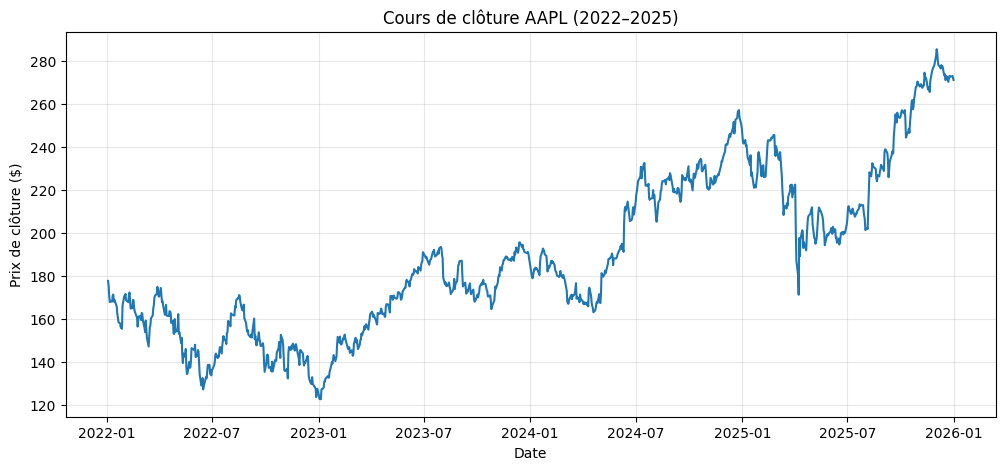

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(data.index, data['Close'])
plt.title("Cours de clôture AAPL (2022–2025)")
plt.xlabel("Date")
plt.ylabel("Prix de clôture ($)")
plt.grid(True, alpha=0.3)
plt.show()

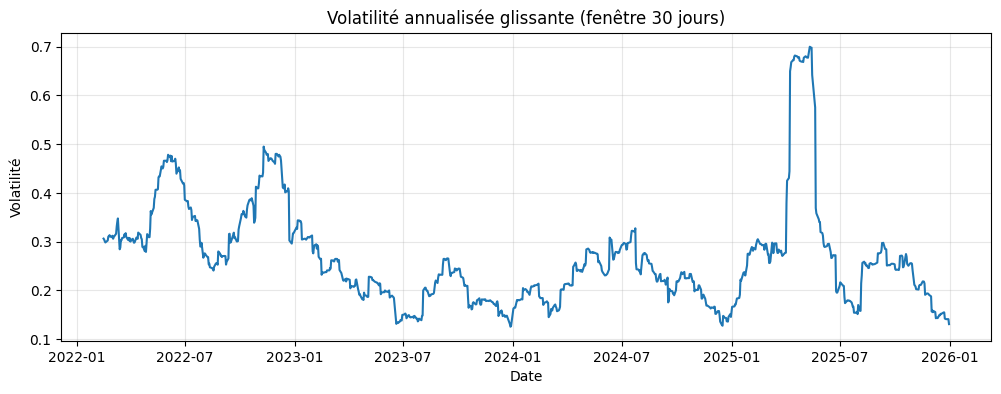

In [8]:
# Rendements journaliers
data['Rendement'] = data['Close'].pct_change()

# Volatilité glissante sur 30 jours (annualisée)
data['Volatilite_30j'] = data['Rendement'].rolling(30).std() * (252 ** 0.5)

plt.figure(figsize=(12, 4))
plt.plot(data.index, data['Volatilite_30j'])
plt.title("Volatilité annualisée glissante (fenêtre 30 jours)")
plt.xlabel("Date")
plt.ylabel("Volatilité")
plt.grid(True, alpha=0.3)
plt.show()

## Note de synthèse — Projet 1

**Contexte et question :** [reprends ta question de cadrage]

**Constats clés :**
1. Dataset propre : aucune valeur manquante, aucun doublon, aucune 
   incohérence (High < Low, prix négatifs, volume nul) sur 1003 
   observations (2022-01-03 à 2025-12-31)
2. Cours de clôture entre 122,83 $ et 285,41 $ sur la période — 
   l'action a plus que doublé
3. Tendance baissière en 2022, reprise progressive 2023-2024, 
   nouveau sommet fin 2025
4. Pic de volatilité marqué autour de [date précise que tu lis sur 
   le graphique] atteignant ~0,70 en annualisé, soit plus du double 
   du niveau habituel — signal d'un choc de marché

**Limites :** analyse univariée (un seul titre), pas de comparaison 
à un indice de référence, volatilité calculée sur fenêtre glissante 
simple (pas de modèle GARCH à ce stade)

**Outils utilisés :** Python, pandas, yfinance, matplotlib